# 01 · Speech processing: transcription and speaker diarization

**Process.** The audio of an episode is turned into time-stamped words (Whisper, through
`faster-whisper`), and each word gets a speaker label (`pyannote.audio` *community-1*). Every
later tool reads these rows: chapters, show notes, relevance, shorts and the hook scorer.

| | |
|---|---|
| Report | §3 *Transcription and Subtitles*, *Speaker Diarization*; §4 *Speech Processing* |
| Code | `backend/app/transcription/`, `backend/app/diarization/` |
| Decisions | 0007 (transcription), 0008 (diarization), 0014 (M9 performance), 0016 (RTX 5070 pass) |
| Benchmark scripts | `experiments/m9-perf/asr_variant.py`, `asr_compare.py`, `bench_transcribe.py` |

This notebook **recomputes** the reported numbers from the stored benchmark outputs and from the
dev database. It does not run Whisper or pyannote again. The audio excerpts and the raw
transcripts stay outside the repository (decision 0026 §3); only aggregates are printed.

In [1]:
import json
import re
import difflib

import jiwer
from yts_nb import *

ASR_DIR = EXPERIMENTS_DATA / "hw-upgrade" / "asr"
print("benchmark outputs:", ASR_DIR.relative_to(EXPERIMENTS_DATA.parent), "| files:", len(list(ASR_DIR.glob("*.json"))))

benchmark outputs: yts-experiments/hw-upgrade/asr | files: 56


## 1. Choosing the Whisper configuration

**Data.** Four 5-minute excerpts of the operator's Spanish episodes (20 minutes in total). There is
no hand-corrected Spanish transcript, so the reference is the most expensive setting:
`large-v3`, `float16`, beam search 5 (`ref`). Each candidate was run once on the RTX 5070 with
`asr_variant.py`; the JSON files keep the words, their timestamps and the run time.

**Metrics.**
- **WER** against the reference, after lower-casing and stripping punctuation (the same
  normalisation as `asr_compare.py`).
- **Drift p95**: the 95th percentile of the start-time difference over aligned words.
- **Time**: the total transcription time of the four excerpts.

In [2]:
def kept(words):
    """(normalised word, start) for every word that survives normalisation (asr_compare.py)."""
    out = []
    for w in words:
        x = re.sub(r"[^\w']+", "", w["word"].lower())
        if x:
            out.append((x, w.get("start")))
    return out


def score_variant(name, ref="ref"):
    excerpts = sorted(p.name.split("__")[1][:-5] for p in ASR_DIR.glob(f"{ref}__*.json"))
    errs = n_words = 0
    secs = 0.0
    drift = []
    for ex in excerpts:
        r_json = json.loads((ASR_DIR / f"{ref}__{ex}.json").read_text())
        h_json = json.loads((ASR_DIR / f"{name}__{ex}.json").read_text())
        rw, hw = kept(r_json["words"]), kept(h_json["words"])
        r, h = [x for x, _ in rw], [x for x, _ in hw]
        o = jiwer.process_words(" ".join(r), " ".join(h))
        errs += o.substitutions + o.deletions + o.insertions
        n_words += len(r)
        secs += h_json["seconds"]
        for tag, a1, a2, b1, b2 in difflib.SequenceMatcher(None, r, h, autojunk=False).get_opcodes():
            if tag == "equal":
                drift += [abs((hw[b1 + k][1] or 0) - (rw[a1 + k][1] or 0)) for k in range(a2 - a1)]
    drift.sort()
    return {"wer": errs / n_words, "drift_p95_s": drift[int(0.95 * (len(drift) - 1))],
            "time_s": secs, "ref_words": n_words, "excerpts": len(excerpts)}


variants = sorted({p.name.split("__")[0] for p in ASR_DIR.glob("*__*.json")} - {"ref"})
rows = []
for v in variants:
    m = re.match(r"(anchor_)?(turbo|v3)_(int8|i8f16|f16)_b(\d+)", v)
    model = "large-v3-turbo" if m.group(2) == "turbo" else "large-v3"
    precision = {"int8": "int8", "i8f16": "int8_float16", "f16": "float16"}[m.group(3)]
    rows.append({"variant": v, "model": model, "precision": precision, "batch": int(m.group(4)),
                 **score_variant(v)})
asr = pd.DataFrame(rows).sort_values(["model", "precision", "batch"]).reset_index(drop=True)
asr.assign(wer=lambda d: (100 * d.wer).round(2)).rename(columns={"wer": "WER %"})

,variant,model,precision,batch,WER %,drift_p95_s,time_s,ref_words,excerpts
0,v3_f16_b4,large-v3,float16,4,14.21,0.30,53.436,3659,4
1,v3_f16_b8,large-v3,float16,8,14.18,0.31,43.308,3659,4
2,v3_f16_b16,large-v3,float16,16,14.16,0.31,34.393,3659,4
3,v3_i8f16_b4,large-v3,int8_float16,4,11.15,0.33,62.160,3659,4
4,v3_i8f16_b8,large-v3,int8_float16,8,11.15,0.34,47.874,3659,4
5,v3_i8f16_b16,large-v3,int8_float16,16,10.82,0.34,35.648,3659,4
6,turbo_f16_b4,large-v3-turbo,float16,4,19.62,0.37,19.989,3659,4
7,turbo_f16_b8,large-v3-turbo,float16,8,19.62,0.37,18.516,3659,4
8,turbo_f16_b16,large-v3-turbo,float16,16,19.51,0.37,16.194,3659,4
9,anchor_turbo_int8_b4,large-v3-turbo,int8,4,17.08,0.39,21.686,3659,4


**Check against the report (Table "Whisper configurations on the RTX 5070").**

In [3]:
reported = {  # variant: (WER, time in s) as printed in the report
    "anchor_turbo_int8_b4": (0.1708, 22), "turbo_i8f16_b16": (0.1700, 15), "turbo_f16_b16": (0.1951, 16),
    "v3_f16_b16": (0.1416, 34), "v3_i8f16_b16": (0.1082, 36),
}
for v, (wer, t) in reported.items():
    row = asr.set_index("variant").loc[v]
    print(compare(f"{v:22s} WER", row.wer, wer, tol=0.00005), f"| time {row.time_s:.0f}s (report {t}s)")

anchor_turbo_int8_b4   WER: recomputed 0.1708 matches the report (0.1708) | time 22s (report 22s)
turbo_i8f16_b16        WER: recomputed 0.1700 matches the report (0.1700) | time 15s (report 15s)
turbo_f16_b16          WER: recomputed 0.1951 matches the report (0.1951) | time 16s (report 16s)
v3_f16_b16             WER: recomputed 0.1416 matches the report (0.1416) | time 34s (report 34s)
v3_i8f16_b16           WER: recomputed 0.1082 matches the report (0.1082) | time 36s (report 36s)


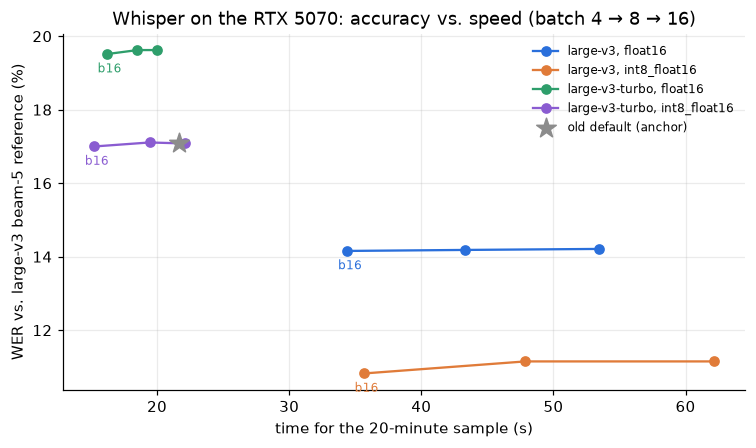

Lowest WER: v3_i8f16_b16 -> 10.82 %, 36 s; anchor 17.08 %, 22 s (1.6x the anchor's time)
Deployed setting (backend config): large-v3 int8_float16 batch 16


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, ((model, prec), g) in enumerate(asr[~asr.variant.str.startswith("anchor")].groupby(["model", "precision"])):
    g = g.sort_values("batch")
    ax.plot(g.time_s, 100 * g.wer, "o-", color=COLORS[i], label=f"{model}, {prec}")
    ax.annotate(f"b{g.batch.iloc[-1]}", (g.time_s.iloc[-1], 100 * g.wer.iloc[-1]),
                textcoords="offset points", xytext=(-6, -12), fontsize=8, color=COLORS[i])
anchor = asr[asr.variant.str.startswith("anchor")].iloc[0]
ax.scatter(anchor.time_s, 100 * anchor.wer, marker="*", s=180, color=GREY, zorder=5, label="old default (anchor)")
ax.set(xlabel="time for the 20-minute sample (s)", ylabel="WER vs. large-v3 beam-5 reference (%)",
       title="Whisper on the RTX 5070: accuracy vs. speed (batch 4 → 8 → 16)")
ax.legend(fontsize=8, frameon=False)
plt.show()

chosen = asr.loc[asr.wer.idxmin()]
print(f"Lowest WER: {chosen.variant} -> {100 * chosen.wer:.2f} %, {chosen.time_s:.0f} s; "
      f"anchor {100 * anchor.wer:.2f} %, {anchor.time_s:.0f} s "
      f"({chosen.time_s / anchor.time_s:.1f}x the anchor's time)")
print("Deployed setting (backend config):", settings.whisper_model, settings.whisper_compute_type,
      "batch", settings.whisper_batch_size)

**Reading.** The `turbo` variants are fast but stay near the anchor's WER, while the `large-v3`
variants are about twice as slow and clearly more accurate. Within one model and precision, a
larger batch is faster at almost the same WER. `large-v3`, `int8_float16`, batch 16 has the lowest
WER and became the default.

**Limitation.** The reference is itself a `large-v3` output, so it favours `large-v3` variants.
The WER measures agreement with the reference, not the true error rate.

## 2. Diarization: batch size does not change the output

On the new GPU the embedding batch was raised from 8 to 32. Both settings were run on the same
full episode (`e15`). The diarization error rate (DER) of one output against the other measures
whether the change altered any label.

In [5]:
import warnings

from pyannote.core import Annotation, Segment
from pyannote.metrics.diarization import DiarizationErrorRate


def read_rttm(path):
    ann = Annotation()
    for line in path.read_text().splitlines():
        f = line.split()
        start, dur, spk = float(f[3]), float(f[4]), f[7]
        ann[Segment(start, start + dur)] = spk
    return ann


full = EXPERIMENTS_DATA / "hw-upgrade" / "full"
b8, b32 = read_rttm(full / "e15_b8.rttm"), read_rttm(full / "e15_b32.rttm")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # UEM = union of both extents: the same episode, so this is exact
    der = DiarizationErrorRate()(b8, b32)
print(f"turns: batch 8 = {len(b8)}, batch 32 = {len(b32)}; speakers: {len(b8.labels())} / {len(b32.labels())}")
print(f"DER(batch 32 vs batch 8) = {der:.4f}")

turns: batch 8 = 1306, batch 32 = 1306; speakers: 5 / 5
DER(batch 32 vs batch 8) = 0.0000


## 3. Diarization on the stored episodes

**Data.** All episodes in the dev database. Each word row carries the speaker label that the
pipeline assigned. No human speaker annotation exists for these episodes, so there is no DER
against a ground truth. The table below describes what the model produced.

In [6]:
per_episode = await sql("""
    select s.upload_id,
           u.duration_seconds / 60.0                       as minutes,
           count(distinct w.speaker_label)                 as speakers,
           count(*)                                        as words
    from transcript_segments s
    join transcript_words w on w.segment_id = s.id
    join uploads u on u.id = s.upload_id
    where w.speaker_label is not null
    group by s.upload_id, u.duration_seconds
    order by s.upload_id
""")
print(f"{len(per_episode)} episodes, {per_episode.minutes.sum() / 60:.1f} h, {per_episode.words.sum():,} words")
per_episode.speakers.value_counts().sort_index().rename_axis("speakers found").to_frame("episodes")

63 episodes, 40.4 h, 405,419 words


,episodes
speakers found,
3,46
4,16
5,1


**Why subtitle cues are split at speaker changes.** The review of a full episode found that much
of the visible "confusion" came from the subtitle cues, not from the model. Each cue showed only
the majority speaker of its Whisper segment, while the word labels were right. Decision 0008 fixed
this by splitting cues at speaker changes.

The query below measures the size of that presentation problem on all stored episodes: the share
of words whose own label differs from the majority speaker of their segment. Those are the words
a majority-only cue would show under the wrong speaker.

Since the batched transcription of M9, Whisper segments are much longer than at the time of the
review. The report's share of *segments* with more than one speaker (7.1 %, measured on the
shorter segments of that time) is therefore not comparable with today's rows. The word share is
the stable measure.

In [7]:
mislabel = await sql("""
    with counts as (
        select s.id, w.speaker_label, count(*) as n
        from transcript_segments s join transcript_words w on w.segment_id = s.id
        where w.speaker_label is not null
        group by s.id, w.speaker_label
    ), seg as (
        select id, sum(n) as words, max(n) as majority_words from counts group by id
    )
    select count(*) as segments, avg(words)::float as words_per_segment,
           sum(words)::float as words, sum(words - majority_words)::float as words_not_majority
    from seg
""")
m = mislabel.iloc[0]
seg_len = await sql("select avg(end_seconds - start_seconds)::float as s from transcript_segments")
print(f"{int(m.segments):,} segments, on average {m.words_per_segment:.0f} words and {seg_len.s[0]:.0f} s long")
print(f"words a majority-only cue would show under the wrong speaker: {m.words_not_majority:,.0f} "
      f"of {m.words:,.0f} ({m.words_not_majority / m.words:.1%})")

5,230 segments, on average 78 words and 27 s long
words a majority-only cue would show under the wrong speaker: 96,164 of 405,419 (23.7%)


## 4. Speed in the deployed pipeline

The `jobs` table keeps the start and end time of every transcription and diarization job. Dividing
the audio duration by the job time gives the real-time factor (× real time; higher is faster).

The stored jobs come from the last full run on the RTX 5070: re-processing an episode replaces
its job rows, so the old machine's jobs are no longer in the database. Two episodes ran in
parallel and shared the GPU, so single values are noisy. The report gives isolated measurements
(decision 0016).

In [8]:
jobs = await sql("""
    select j.tool_type, j.started_at, extract(epoch from j.completed_at - j.started_at)::float as seconds,
           u.duration_seconds
    from jobs j join uploads u on u.id = j.upload_id
    where j.status = 'succeeded' and j.tool_type in ('transcribe', 'diarize')
      and j.started_at is not null and j.completed_at is not null
""")
jobs["x_real_time"] = jobs.duration_seconds / jobs.seconds
started = pd.to_datetime(jobs.started_at)
print("job dates:", started.min().date(), "to", started.max().date())
jobs.groupby("tool_type").x_real_time.describe()[["count", "50%", "min", "max"]].rename(columns={"50%": "median"})

job dates: 2026-11-07 to 2026-11-08


,count,median,min,max
tool_type,,,,
diarize,68.0,33.276,2.749,65.391
transcribe,68.0,31.780,7.874,51.271


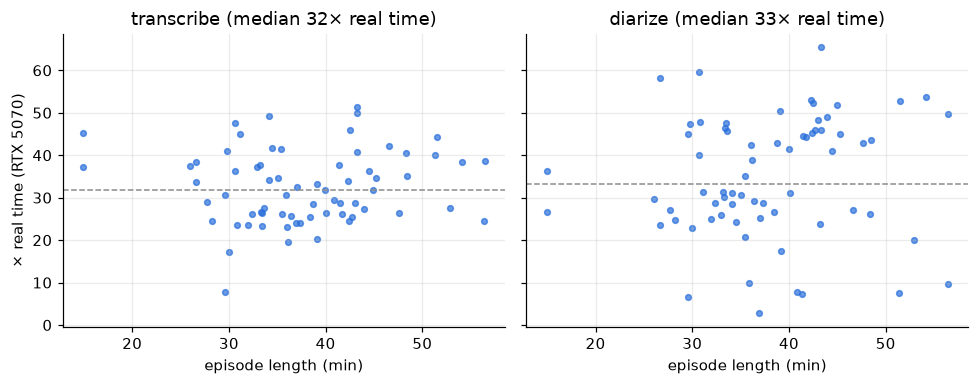

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, tool in zip(axes, ["transcribe", "diarize"]):
    g = jobs[jobs.tool_type == tool]
    ax.scatter(g.duration_seconds / 60, g.x_real_time, s=14, alpha=0.7)
    ax.axhline(g.x_real_time.median(), color=GREY, lw=1, ls="--")
    ax.set(title=f"{tool} (median {g.x_real_time.median():.0f}× real time)", xlabel="episode length (min)")
axes[0].set_ylabel("× real time (RTX 5070)")
plt.tight_layout()
plt.show()

## Summary

- `large-v3` in `int8_float16` with batch 16 has the lowest WER against the reference, and became
  the default. The reference bias above is the main caveat.
- Raising the diarization batch to 32 left the output unchanged (DER 0 between the settings).
- Without human annotation, diarization quality was judged by review. The stored labels show how
  many words a majority-only subtitle cue would mislabel, which is why cues are split at speaker
  changes.